
<h2 style="break-before: page; page-break-before: always;">
Q2.1
</h2>

In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split

# read csv
df = pd.read_csv('A2Q2-troublesome-data.csv', index_col=0,
                 header=0,
                 names=['index', 'x1', 'x2', 'target'])

# seperate features and target/label value
X = df[['x1', 'x2']]
y = df['target']

# first split: 80% Training, 20% Temporary (to be split again)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=123123
)

# second split: Split the 20% Temporary evenly into 10% 
# validation and 10% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=123123
)


<h2 style="break-before: page; page-break-before: always;">
Q2.2
</h2>

In [22]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score

# knn classifier
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
knn_preds = knn.predict(X_val)
knn_acc = accuracy_score(y_val, knn_preds)

# decision tree classifier
dectree = DecisionTreeClassifier(random_state=123123)
dectree.fit(X_train, y_train)
dectree_preds = dectree.predict(X_val)
dectree_acc = accuracy_score(y_val, dectree_preds)

# linear regression
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
# predict continuous values then make threshold at 0.5 to convert to classes
# 0 or 1
lin_reg_preds_cont = lin_reg.predict(X_val)
lin_reg_preds = (lin_reg_preds_cont >= 0.5).astype(int)
lin_reg_acc = accuracy_score(y_val, lin_reg_preds)

# logistic regression classifier
log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)
log_reg_preds = log_reg.predict(X_val)
log_reg_acc = accuracy_score(y_val, log_reg_preds)

print(f"KNN Accuracy: {knn_acc:.4f}")
print(f"Decision Tree Accuracy: {dectree_acc:.4f}")
print(f"Linear Regression Accuracy: {lin_reg_acc:.4f}")
print(f"Logistic Regression Accuracy: {log_reg_acc:.4f}")

KNN Accuracy: 0.9930
Decision Tree Accuracy: 0.9880
Linear Regression Accuracy: 0.9880
Logistic Regression Accuracy: 0.9920


<h2 style="break-before: page; page-break-before: always;">
Q2.4
</h2>

In [23]:
class_counts = y.value_counts()
print(f"Class Counts: {class_counts}")

Class Counts: target
0.0    9900
1.0     100
Name: count, dtype: int64


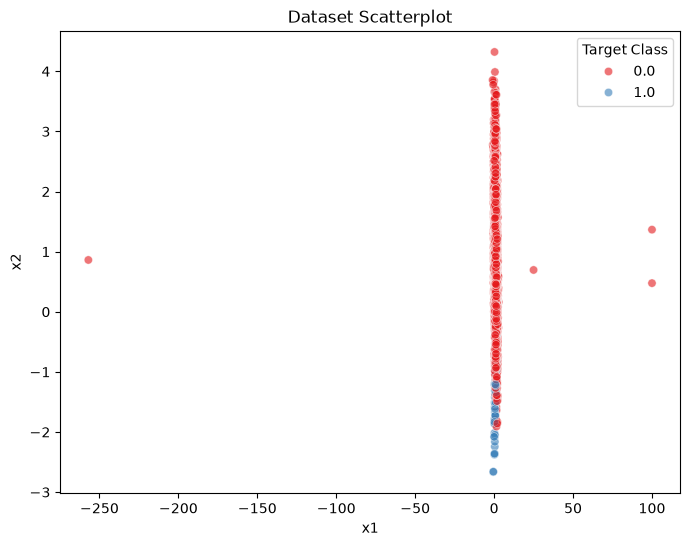

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X['x1'], y=X['x2'], hue=y, palette='Set1', alpha=0.6)
plt.title('Dataset Scatterplot')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend(title='Target Class')
plt.show()

<h2 style="break-before: page; page-break-before: always;">
Q2.5
</h2>

In [25]:
from sklearn.metrics import confusion_matrix

model_predictions = {
    "KNN": knn_preds,
    "Decision Tree": dectree_preds,
    "Linear Regression": lin_reg_preds,
    "Logistic Regression": log_reg_preds
}

for name, preds in model_predictions.items():
    cm = confusion_matrix(y_val, preds)
    
    # ravel flattens the 2x2 matrix into 4 variables
    tn, fp, fn, tp = cm.ravel()
    
    # calculate the fraction of true class-0 correctly classified
    frac_class_0 = tn / (tn + fp)
    
    # calculate the fraction of true class-1 correctly classified
    frac_class_1 = tp / (tp + fn)
    
    # Report the results
    print(f"--- {name} ---")
    print(f"Confusion Matrix:\n{cm}")
    print(f"Fraction Class-0 Correct: {frac_class_0:.4f}")
    print(f"Fraction Class-1 Correct: {frac_class_1:.4f}\n")

--- KNN ---
Confusion Matrix:
[[986   2]
 [  5   7]]
Fraction Class-0 Correct: 0.9980
Fraction Class-1 Correct: 0.5833

--- Decision Tree ---
Confusion Matrix:
[[981   7]
 [  5   7]]
Fraction Class-0 Correct: 0.9929
Fraction Class-1 Correct: 0.5833

--- Linear Regression ---
Confusion Matrix:
[[988   0]
 [ 12   0]]
Fraction Class-0 Correct: 1.0000
Fraction Class-1 Correct: 0.0000

--- Logistic Regression ---
Confusion Matrix:
[[987   1]
 [  7   5]]
Fraction Class-0 Correct: 0.9990
Fraction Class-1 Correct: 0.4167



<h2 style="break-before: page; page-break-before: always;">
Q2.7
</h2>

In [26]:
from sklearn.metrics import f1_score
for name, preds in model_predictions.items():
    # Calculate F1 score for the positive class (class 1)
    f1 = f1_score(y_val, preds, pos_label=1, zero_division=0)
    
    print(f"{name}: {f1:.4f}")

KNN: 0.6667
Decision Tree: 0.5385
Linear Regression: 0.0000
Logistic Regression: 0.5556


<h2 style="break-before: page; page-break-before: always;">
Q2.8
</h2>

In [27]:
from sklearn.utils import resample

# combine inputs and targets into single
# train_data dataframe
train_data = pd.concat([X_train, y_train], axis=1)

# seperate majority (0) and minority(1) classes
majority = train_data[train_data['target'] == 0]
minority = train_data[train_data['target'] == 1]

# randomly duplicate the minority-class examples to match
# the total amount of majority class counts
minority_upsampled = resample(minority, replace=True,
                              n_samples=len(majority), random_state=123123)

# combine the majority class with upsamples minority class
train_upsampled = pd.concat([majority, minority_upsampled])

X_train_upsampled = train_upsampled[['x1', 'x2']]
y_train_upsampled = train_upsampled['target']

models = {
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=123123),
    "Linear Regression": LinearRegression(),
    "Logistic Regression": LogisticRegression()
}

for name, model in models.items():
    # train on the oversampled_data
    model.fit(X_train_upsampled, y_train_upsampled)

    # predict on the validation set
    if name == "Linear Regression":
        preds_cont = model.predict(X_val)
        preds = (preds_cont >= 0.5).astype(int)
    else:
        preds = model.predict(X_val)

    # generate confusion matrix
    cm = confusion_matrix(y_val, preds)
    tn, fp, fn, tp = cm.ravel()

    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = (tp) / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    print(f"\nModel : {name}")
    print(f"Confusion Matrix: \n{cm}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")    



Model : KNN
Confusion Matrix: 
[[975  13]
 [  4   8]]
Accuracy: 0.9830
Precision: 0.3810
Recall: 0.6667

Model : Decision Tree
Confusion Matrix: 
[[983   5]
 [  5   7]]
Accuracy: 0.9900
Precision: 0.5833
Recall: 0.5833

Model : Linear Regression
Confusion Matrix: 
[[877 111]
 [  0  12]]
Accuracy: 0.8890
Precision: 0.0976
Recall: 1.0000

Model : Logistic Regression
Confusion Matrix: 
[[901  87]
 [  0  12]]
Accuracy: 0.9130
Precision: 0.1212
Recall: 1.0000


<h2 style="break-before: page; page-break-before: always;">
Q2.9
</h2>

In [28]:
majority_downsampled = resample(majority, replace=False,
                                n_samples=len(minority),
                                random_state=123123)

train_downsampled = pd.concat([majority_downsampled, minority])

X_train_down = train_downsampled[['x1', 'x2']]
y_train_down = train_downsampled['target']

for name, model in models.items():
    # train on the oversampled_data
    model.fit(X_train_down, y_train_down)

    # predict on the validation set
    if name == "Linear Regression":
        preds_cont = model.predict(X_val)
        preds = (preds_cont >= 0.5).astype(int)
    else:
        preds = model.predict(X_val)

    # generate confusion matrix
    cm = confusion_matrix(y_val, preds)
    tn, fp, fn, tp = cm.ravel()

    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = (tp) / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    print(f"\nModel : {name}")
    print(f"Confusion Matrix: \n{cm}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")  


Model : KNN
Confusion Matrix: 
[[883 105]
 [  0  12]]
Accuracy: 0.8950
Precision: 0.1026
Recall: 1.0000

Model : Decision Tree
Confusion Matrix: 
[[907  81]
 [  1  11]]
Accuracy: 0.9180
Precision: 0.1196
Recall: 0.9167

Model : Linear Regression
Confusion Matrix: 
[[878 110]
 [  0  12]]
Accuracy: 0.8900
Precision: 0.0984
Recall: 1.0000

Model : Logistic Regression
Confusion Matrix: 
[[908  80]
 [  0  12]]
Accuracy: 0.9200
Precision: 0.1304
Recall: 1.0000


<h2 style="break-before: page; page-break-before: always;">
Q2.10
</h2>

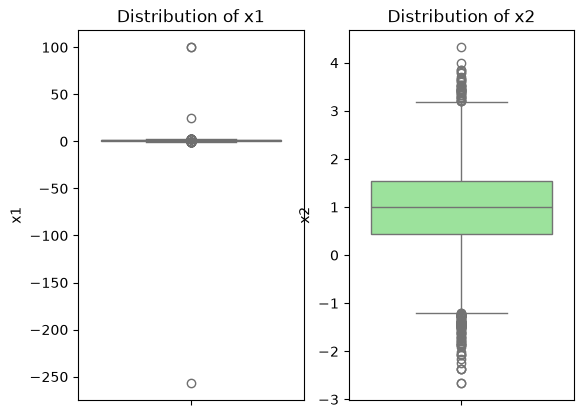

In [29]:
plt.Figure((10,5))

plt.subplot(1, 2, 1)
sns.boxplot(y=X['x1'], color='skyblue')
plt.title('Distribution of x1')

plt.subplot(1, 2, 2)
sns.boxplot(y=X['x2'], color='lightgreen')
plt.title('Distribution of x2')

plt.show()

<h2 style="break-before: page; page-break-before: always;">
Q2.11
</h2>

In [30]:
number_of_neighbours = [1,3,5]

for neighbours in number_of_neighbours:
    model = KNeighborsClassifier(n_neighbors=neighbours)

    # train on the original training data
    model.fit(X_train, y_train)

    # predict validation set
    preds = model.predict(X_val)

    # get confusion matrix
    cm = confusion_matrix(y_val, preds)

    print(f"Confusion Matrix for KNN with {neighbours} neighbours")
    print(f"{cm}")


Confusion Matrix for KNN with 1 neighbours
[[984   4]
 [  5   7]]
Confusion Matrix for KNN with 3 neighbours
[[985   3]
 [  5   7]]
Confusion Matrix for KNN with 5 neighbours
[[986   2]
 [  5   7]]


<h2 style="break-before: page; page-break-before: always;">
Q2.12
</h2>

In [31]:
max_depths = [1,2,3]

for depth in max_depths:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=123123)

    dt.fit(X_train, y_train)

    # predict on the validation set
    preds = dt.predict(X_val)
    
    cm = confusion_matrix(y_val, preds)
    print(f"max_depth={depth}:\n{cm}\n")


max_depth=1:
[[984   4]
 [  5   7]]

max_depth=2:
[[988   0]
 [  5   7]]

max_depth=3:
[[988   0]
 [  5   7]]

